# Proyecto Drugs: Limpieza

## Metadata

In [ ]:
#--- Project Metadata
from datetime import datetime
AUTOR = "Mgtr. Ignacio Osorio"
FECHA_MODIFICACION = datetime.now().strftime("%d/%m/%Y %H:%M:%S")

print(f"Autor: {AUTOR}")
print(f"Última modificación: {FECHA_MODIFICACION}\n" + "-"*40)

Autor: Mgtr. Ignacioo Osorio
Última modificación: 16/10/2026 19:53:38
----------------------------------------


## Entorno

In [78]:
import pandas as pd
import numpy as np

# ruta completa donde se encuentra Utils.py
import sys
sys.path.append('C:/Users/games/OneDrive/DS/Clases/Utils')
from descriptive_analysis import *

## Hallazgos Claves
| Objetivos | Descripción | Columnas | Hecho |
| :--- | :--- | :--- | :--- |
| Eliminar última fila | | | |
| Renombrar columnas | | | |
| Eliminar filas con valores nulos (30%) | |1 | |
| Eliminar columnas con valores nulos (50%) | |OtherSignifican, Other, LocationifOther, InjuryState, InjuryCounty | |
| Eliminar columnas con alta cardinalidad | |Ninguna | |
| Eliminar columnas con desbalance extremo de clases | |MannerofDeath, ResidenceState | |
| Eliminar columnas con texto libre no estructuradoo | |COD, DescriptionofInjury, OtherSignifican, Morphine_NotHeroin | |
| Eliminar columnas por estar duplicada | |Ninguna | |
| Eliminar columnas por costo de recolección en producción | |Ninguna | |
| Eliminar columnas por fuga de información | |Ninguna | |
| Eliminar filas duplicadas | |1 | |
| Eliminar filas con subconjuntos duplicados | | | |
| Ajuste de tipos de datos| | | |
| Categoría | | | |
| Inconsistencia (Perú, Perú; símbolos raros, fechas; edades; negativos; ceros) | | | |
| Codificación | | | |
| Otros| | | |

Si predices número → cuida forma, outliers y escala <br>
Si predices clase → cuida proporciones, separación y codificación (ex. one-hot)

## Dataset

### Carga

In [79]:
import os
ruta=os.getcwd()
ruta_csv = 'drug_deaths.csv'
df = pd.read_csv(ruta_csv, index_col=0)

In [80]:
ruta_excel = 'cambios_drogas.xlsx'
df_city = pd.read_excel(ruta_excel, sheet_name='city')
df_county = pd.read_excel(ruta_excel, sheet_name='county')
df_todo = pd.read_excel(ruta_excel, sheet_name='todo')

### Muestra

In [81]:
pd.set_option('display.max_columns', None)
df.head(3)

,ID,Date,DateType,Age,Sex,Race,ResidenceCity,ResidenceCounty,ResidenceState,DeathCity,DeathCounty,Location,LocationifOther,DescriptionofInjury,InjuryPlace,InjuryCity,InjuryCounty,InjuryState,COD,OtherSignifican,Heroin,Cocaine,Fentanyl,Fentanyl_Analogue,Oxycodone,Oxymorphone,Ethanol,Hydrocodone,Benzodiazepine,Methadone,Amphet,Tramad,Morphine_NotHeroin,Hydromorphone,Other,OpiateNOS,AnyOpioid,MannerofDeath,DeathCityGeo,ResidenceCityGeo,InjuryCityGeo
0,14-0273,06/28/2014 12:00:00 AM,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,substance,NaN,NaN,NaN,NaN,"Acute fent, hydrocod, benzodiazepine",NaN,0,0,1,0.0,0,0,0,1,1,0,0,0,0,0,NaN,0,0,Accident,"CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)"
1,13-0102,03/21/2013 12:00:00 AM,0.0,48.0,Male,Black,NORWALK,NaN,NaN,NORWALK,FAIRFIELD,Hospital,NaN,NaN,NaN,NaN,NaN,NaN,Cocaine Intoxication,NaN,0,1,0,0.0,0,0,0,0,0,0,0,0,0,0,NaN,0,0,Accident,"Norwalk, CT\n(41.11805, -73.412906)","NORWALK, CT\n(41.11805, -73.412906)","CT\n(41.575155, -72.738288)"
2,16-0165,03/13/2016 12:00:00 AM,0.0,30.0,Female,White,SANDY HOOK,FAIRFIELD,CT,DANBURY,NaN,Hospital,NaN,Substance Abuse,Unknown,UNKNOWN,NaN,NaN,Acute Heroin and Cocaine Intoxication,NaN,1,1,0,0.0,0,0,0,0,0,0,0,0,0,0,NaN,0,1,Accident,"Danbury, CT\n(41.393666, -73.451539)","SANDY HOOK, CT\n(41.419998, -73.282501)",NaN


In [82]:
df.tail(3)

,ID,Date,DateType,Age,Sex,Race,ResidenceCity,ResidenceCounty,ResidenceState,DeathCity,DeathCounty,Location,LocationifOther,DescriptionofInjury,InjuryPlace,InjuryCity,InjuryCounty,InjuryState,COD,OtherSignifican,Heroin,Cocaine,Fentanyl,Fentanyl_Analogue,Oxycodone,Oxymorphone,Ethanol,Hydrocodone,Benzodiazepine,Methadone,Amphet,Tramad,Morphine_NotHeroin,Hydromorphone,Other,OpiateNOS,AnyOpioid,MannerofDeath,DeathCityGeo,ResidenceCityGeo,InjuryCityGeo
5102,18-0646,08/14/2018 12:00:00 AM,0.0,30.0,Male,White,LAWRENCEVILLE,TIOGA,PA,DANBURY,FAIRFIELD,Other,NaN,Drug abuse,Hotel or Motel,DANBURY,FAIRFIELD,NaN,"Multidrug Toxicity Including Heroin, Fentanyl,...",NaN,1,0,1,1.0,0,0,0,0,0,0,0,1,0,0,NaN,0,1,Accident,"DANBURY, CT\n(41.393666, -73.451539)",NaN,"DANBURY, CT\n(41.393666, -73.451539)"
5103,14-0124,03/16/2014 12:00:00 AM,0.0,33.0,Male,White,HARTFORD,NaN,NaN,WINDSOR,NaN,Other,NaN,Substance Abuse,Hotel or Motel,NaN,NaN,NaN,Acute Fentanyl intoxication,Cardiac hypertrophy,0,0,1,0.0,0,0,0,0,0,0,0,0,0,0,NaN,0,0,Accident,"WINDSOR, CT\n(41.852781, -72.64379)","HARTFORD, CT\n(41.765775, -72.673356)","CT\n(41.575155, -72.738288)"
5104,16-0637,09/15/2016 12:00:00 AM,0.0,33.0,Male,White,THOMASTON,LITCHFIELD,CT,WATERBURY,NaN,Other,By Railroad Tracks,Substance Abuse,Railroad Track,"WATERBURY, CT",NaN,NaN,Acute Heroin Intoxication,NaN,1,0,0,0.0,0,0,0,0,0,0,0,0,0,0,NaN,0,1,Accident,"WATERBURY, CT\n(41.554261, -73.043069)","THOMASTON, CT\n(41.674124, -73.073189)","WATERBURY, CT, CT\n(41.554261, -73.043069)"


## Nombre de Columnas
### Limpieza

In [83]:
print("=== ORIGINAL ===")
print(df.columns.tolist())

df.columns = (
    df.columns.to_series()  # Convertimos a Serie para habilitar el diccionario
    .str.strip() # Quita espacios al inicio y final *
    .str.replace(r"\s+", " ", regex=True)  # Reemplaza múltiples espacios internos por solo uno
    .str.replace(r"[^\w\s]", "", regex=True)  # Borra caracteres especiales
    .str.replace(r"(?<=[a-z0-9])(?=[A-Z])", "_", regex=True)  # Separa camelCase
    .str.lower() # Convierte todo a minúsculas *
    .str.replace(" ", "_") # Cambia espacios por guiones bajos 
    .str.replace(r"_+", "_", regex=True)  # Quita guiones duplicados
    .str.replace(r"^_|_$", "", regex=True)  # Quita guiones en extremos
    )
    
print("\n=== CAMBIOS APLICADOS ===")
print(df.columns.tolist())

=== ORIGINAL ===
['ID', 'Date', 'DateType', 'Age', 'Sex', 'Race', 'ResidenceCity', 'ResidenceCounty', 'ResidenceState', 'DeathCity', 'DeathCounty', 'Location', 'LocationifOther', 'DescriptionofInjury', 'InjuryPlace', 'InjuryCity', 'InjuryCounty', 'InjuryState', 'COD', 'OtherSignifican', 'Heroin', 'Cocaine', 'Fentanyl', 'Fentanyl_Analogue', 'Oxycodone', 'Oxymorphone', 'Ethanol', 'Hydrocodone', 'Benzodiazepine', 'Methadone', 'Amphet', 'Tramad', 'Morphine_NotHeroin', 'Hydromorphone', 'Other', 'OpiateNOS', 'AnyOpioid', 'MannerofDeath', 'DeathCityGeo', 'ResidenceCityGeo', 'InjuryCityGeo']

=== CAMBIOS APLICADOS ===
['id', 'date', 'date_type', 'age', 'sex', 'race', 'residence_city', 'residence_county', 'residence_state', 'death_city', 'death_county', 'location', 'locationif_other', 'descriptionof_injury', 'injury_place', 'injury_city', 'injury_county', 'injury_state', 'cod', 'other_significan', 'heroin', 'cocaine', 'fentanyl', 'fentanyl_analogue', 'oxycodone', 'oxymorphone', 'ethanol', 'hydr

### Renombrado

In [84]:
df = df.rename(columns={'locationif_other': 'location_if_other', 'descriptionof_injury': 'description_of_injury' , 'mannerof_death': 'manner_of_death'})

## Distribución de Columnas

In [85]:
ids, num, bina, tiem, cat = separar_variables(df, None)

-> IDENTIFICADORES: {'tipo': 'ID', 'cantidad': 1, 'columnas': ['id']}

-> NUMERICAS: {'tipo': 'Numerica', 'cantidad': 1, 'columnas': ['age']}

-> BINARIAS: {'tipo': 'Binaria', 'cantidad': 14, 'columnas': ['date_type', 'heroin', 'cocaine', 'fentanyl_analogue', 'oxycodone', 'oxymorphone', 'ethanol', 'hydrocodone', 'benzodiazepine', 'methadone', 'amphet', 'tramad', 'hydromorphone', 'opiate_nos']}

-> TIEMPO: {'tipo': 'tiema', 'cantidad': 1, 'columnas': ['date']}

-> CATEGORICAS: {'tipo': 'Categorica', 'cantidad': 24, 'columnas': ['sex', 'race', 'residence_city', 'residence_county', 'residence_state', 'death_city', 'death_county', 'location', 'location_if_other', 'description_of_injury', 'injury_place', 'injury_city', 'injury_county', 'injury_state', 'cod', 'other_significan', 'fentanyl', 'morphine_not_heroin', 'other', 'any_opioid', 'manner_of_death', 'death_city_geo', 'residence_city_geo', 'injury_city_geo']}



In [86]:
# Creas un DataFrame para cada grupo con sus datos correspondientes
# target = por definir 
df_ids = df[['id']]
df_num = df[['age']]
df_bina = df[['sex', 'date_type', 'any_opioid', 'injury_place', 'fentanyl', 'heroin', 'cocaine', 'fentanyl_analogue', 'oxycodone', 'oxymorphone', 'ethanol', 'hydrocodone', 'benzodiazepine', 'methadone', 'amphet', 'tramad', 'hydromorphone', 'opiate_nos', 'location']]
df_tiem = df[['date']]
df_cat = df[['race','location']]

## Estadistica Descriptiva


#### General

In [87]:
basic_info(df)


RESUMEN GENERAL DE DATOS
Dimensiones → Filas: 5,105 | Columnas: 41
                         dtype  mem_default_bytes  mem_deep_bytes  unique  %_unique  zeros  negatives   min   max range
id                         str              40840          285880    5105    100.00      0          0  None  None  None
date                       str              40840          362377    2098     41.10      0          0  None  None  None
date_type              float64              40840           40840       2      0.04   2822          0   0.0   1.0   1.0
age                    float64              40840           40840      65      1.27      0          0  14.0  87.0  73.0
sex                        str              40840          273092       3      0.06      0          0  None  None  None
race                       str              40840          281528      11      0.22      0          0  None  None  None
residence_city             str              40840          290992     370      7.25      0  

#### Numericas

In [88]:
description(df_num)


ESTADÍSTICAS DESCRIPTIVAS


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis,CV,outliers,outliers_%
age,5102.0,41.964916,12.336639,14.0,32.0,42.0,52.0,87.0,0.101118,-0.860774,0.293975,2,0.04



### VERIFICACIONES (CHECKS) ###

    ASIMETRÍA / SKEWNESS (|skew|):
    • < 1              : Aproximadamente simétrica → OK
    • 1–2              : Moderadamente sesgada → considerar transformación log/sqrt
    • > 2              : Altamente sesgada → transformación recomendada
    
    CURTOSIS:
    • ≈ 3              : Colas normales (mesocúrtica) → OK
    • < 3              : Colas ligeras (platicúrtica) → OK
    • > 3              : Colas pesadas (leptocúrtica) → verificar outliers
    
    COEFICIENTE DE VARIACIÓN (CV = std/mean):
    • < 0.5            : Baja variabilidad → variable estable
    • 0.5–1.0          : Variabilidad moderada → aceptable
    • > 1.0            : Alta variabilidad → considerar escalado/transformación
    
    OUTLIERS (%):
    • < 5%             : Bajo → OK
    • 5–10%            : Moderado → considerar tratamiento
    • > 10%            : Alto → investigar y potencialmente eliminar/acotar (cap)
    
    LÍMITES DE OUTLIERS:
    • lower_bound = Q1 - 1

#### Categoricas

In [89]:
reporte_unicos_robusto(df_cat, limite=10)


🔹 COLUMNA: race | Valores Únicos: 12
⚠️ Mostrando solo el top 10 (hay demasiadas categorías):


,Conteo,%
race,,
White,4004,78.43
"Hispanic, White",561,10.99
Black,433,8.48
"Hispanic, Black",24,0.47
Unknown,23,0.45
"Asian, Other",18,0.35
Asian Indian,14,0.27
<Nulos>,13,0.25
Other,11,0.22



🔹 COLUMNA: location | Valores Únicos: 7


,Conteo,%
location,,
Residence,2677,52.44
Hospital,1626,31.85
Other,773,15.14
<Nulos>,24,0.47
Convalescent Home,3,0.06
Nursing Home,1,0.02
Hospice,1,0.02


## Simbolos Raros

In [90]:
analizar_simbolos(df)

## Columna: id
Símbolos detectados: ['-']
Ejemplos de celdas (mostrando 3 de 5105):
 - 14-0273
 - 13-0102
 - 16-0165
----------------------------------------
## Columna: date
Símbolos detectados: [':', '/']
Ejemplos de celdas (mostrando 3 de 5103):
 - 06/28/2014 12:00:00 AM
 - 03/21/2013 12:00:00 AM
 - 03/13/2016 12:00:00 AM
----------------------------------------
## Columna: race
Símbolos detectados: [',']
Ejemplos de celdas (mostrando 3 de 604):
 - Asian, Other
 - Hispanic, White
 - Hispanic, White
----------------------------------------
## Columna: residence_city
Símbolos detectados: ['-']
Ejemplos de celdas (mostrando 3 de 3):
 - VERNON-ROCKVILLE
 - VERNON-ROCKVILLE
 - HASTINGS-ON-HUDSON
----------------------------------------
## Columna: residence_county
Símbolos detectados: ['-']
Ejemplos de celdas (mostrando 1 de 1):
 - MIAMI-DADE
----------------------------------------
## Columna: death_city
Símbolos detectados: ['-']
Ejemplos de celdas (mostrando 1 de 1):
 - VERNON-ROCKVIL

## Nulos


PATRONES VISUALES DE DATOS FALTANTES


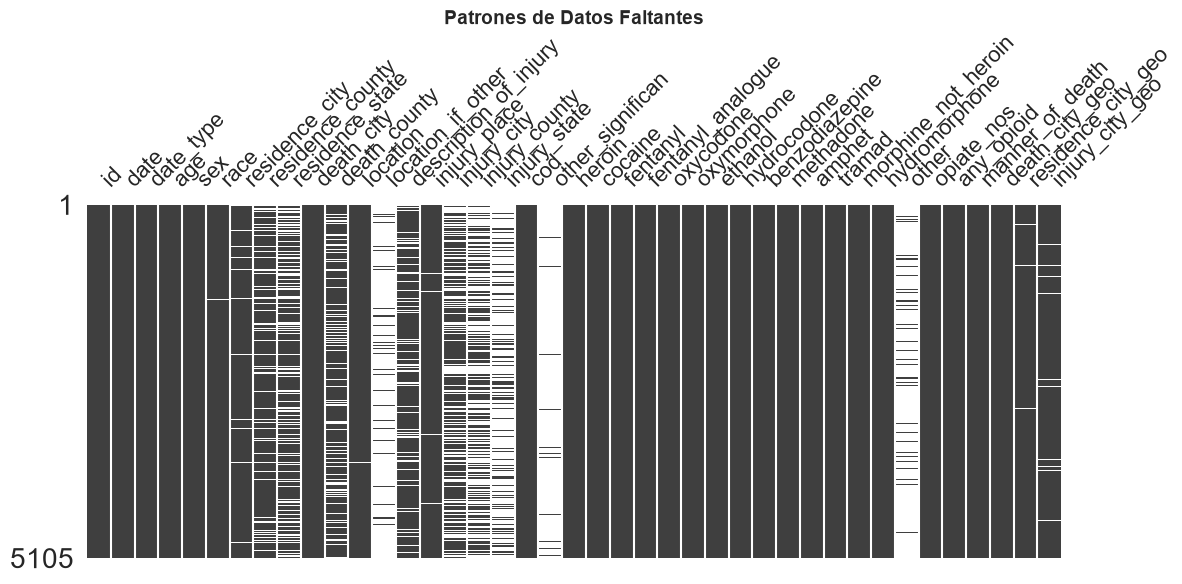


RESUMEN DE DATOS FALTANTES
                       null_count  %_missing  fake_nulls fake_values_found  total_missing  %_total
other_significan             4936      96.69           0                []           4936    96.69
other                        4670      91.48           0                []           4670    91.48
location_if_other            4515      88.44           0                []           4515    88.44
injury_state                 3681      72.11           0                []           3681    72.11
injury_county                2741      53.69           0                []           2741    53.69
injury_city                  1756      34.40           0                []           1756    34.40
residence_state              1549      30.34           0                []           1549    30.34
death_county                 1100      21.55           0                []           1100    21.55
residence_county              797      15.61           0                []       

In [91]:
null_audit(df)

In [92]:
get_missing_raw_report(df, threshold=0.30)

,id,date,date_type,age,sex,race,residence_city,residence_county,residence_state,death_city,death_county,location,location_if_other,description_of_injury,injury_place,injury_city,injury_county,injury_state,cod,other_significan,heroin,cocaine,fentanyl,fentanyl_analogue,oxycodone,oxymorphone,ethanol,hydrocodone,benzodiazepine,methadone,amphet,tramad,morphine_not_heroin,hydromorphone,other,opiate_nos,any_opioid,manner_of_death,death_city_geo,residence_city_geo,injury_city_geo
0,14-0273,06/28/2014 12:00:00 AM,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,substance,NaN,NaN,NaN,NaN,"Acute fent, hydrocod, benzodiazepine",NaN,0,0,1,0.0,0,0,0,1,1,0,0,0,0,0,NaN,0,0,Accident,"CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)"
12,15-0728,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Unknown,NaN,NaN,NaN,Ruptured Aneurysm of right Iliac Artery with H...,Acute Cocaine,0,1,0,0.0,0,0,0,0,0,0,0,0,0,0,NaN,0,0,Accident,"CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)"
4887,15-0309,06/28/2015 12:00:00 AM,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Other indoor Area,NORTH WINDHAM,WINDHAM,CT,Acute fentanyl intox,NaN,0,0,1,0.0,0,0,0,0,0,0,0,0,0,0,NaN,0,1,NaN,"CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)","NORTH WINDHAM, CT\n(41.749401, -72.154999)"



### VERIFICACIÓN (CHECK) ###
-Considerar eliminar filas con más del 30% de faltantes en sus columnas


## Duplicados

### Duplicados en Filas

In [93]:
check_duplicates(df, None)


ANÁLISIS DE DUPLICADOS
Filas con None duplicado: 0 (0.00%)
✓ No se encontraron duplicados


In [94]:
df = df.drop_duplicates(subset=None, keep='first')

### Duplicados en Columnas
No aplica, no hay columnas como ID, nombres, fecha de nacimiento para idetificar duplicados de ese tipo

## Eliminación de Columnas

In [95]:
df.columns

Index(['id', 'date', 'date_type', 'age', 'sex', 'race', 'residence_city',
       'residence_county', 'residence_state', 'death_city', 'death_county',
       'location', 'location_if_other', 'description_of_injury',
       'injury_place', 'injury_city', 'injury_county', 'injury_state', 'cod',
       'other_significan', 'heroin', 'cocaine', 'fentanyl',
       'fentanyl_analogue', 'oxycodone', 'oxymorphone', 'ethanol',
       'hydrocodone', 'benzodiazepine', 'methadone', 'amphet', 'tramad',
       'morphine_not_heroin', 'hydromorphone', 'other', 'opiate_nos',
       'any_opioid', 'manner_of_death', 'death_city_geo', 'residence_city_geo',
       'injury_city_geo'],
      dtype='str')

In [29]:
# print("Valores y cantidades:\n", df['InjuryPlace'].value_counts(dropna=False))
# print("\nPorcentajes (%):\n", df['InjuryPlace'].value_counts(normalize=True, dropna=False) * 100)

### Por Nulos (50% o +)

In [30]:
df = df.drop(columns =['location_if_other', 'cod', 'other', 'injury_state', 'other_significan' ])

### Por Alta Cardinalidad
La columna id se está quedando como índice

### Por Desbalance Extremo de Clases

In [31]:
df = df.drop(columns =['manner_of_death', 'residence_state' ])

### Por Texto Libre No Estructurado

In [32]:
df = df.drop(columns =['description_of_injury', 'morphine_not_heroin' ])

### Por Duplicación
Ninguna

### Por Costo de Recolección en Producción
Ninguna

### Por Fuga de Información
Ninguna

### Strings a Index

In [33]:
df = df.set_index("id")
df.head(2)

,date,date_type,age,sex,race,residence_city,residence_county,death_city,death_county,location,injury_place,injury_city,injury_county,heroin,cocaine,fentanyl,fentanyl_analogue,oxycodone,oxymorphone,ethanol,hydrocodone,benzodiazepine,methadone,amphet,tramad,hydromorphone,opiate_nos,any_opioid,death_city_geo,residence_city_geo,injury_city_geo
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
14-0273,06/28/2014 12:00:00 AM,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,0,1,0.0,0,0,0,1,1,0,0,0,0,0,0,"CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)","CT\n(41.575155, -72.738288)"
13-0102,03/21/2013 12:00:00 AM,0.0,48.0,Male,Black,NORWALK,NaN,NORWALK,FAIRFIELD,Hospital,NaN,NaN,NaN,0,1,0,0.0,0,0,0,0,0,0,0,0,0,0,0,"Norwalk, CT\n(41.11805, -73.412906)","NORWALK, CT\n(41.11805, -73.412906)","CT\n(41.575155, -72.738288)"


## Tipos y Contenido

### Target
Por definir

### Columnas Númericas

In [34]:
pd.set_option("display.max_rows", 10) # <-- si pones None en vez de 10, se vera todos

In [35]:
df_num.columns

Index(['age'], dtype='str')

#### Edad

In [36]:
print("=== ORIGINAL ===")
print("zeros, negatives, min, max, range verlos en 'Estadistica Descriptiva-General'")
print("mem_default_bytes, mem_deep_bytes en 'Estadistica Descriptiva-General' para ver simbolos raros")

df["age"].value_counts()

=== ORIGINAL ===
zeros, negatives, min, max, range verlos en 'Estadistica Descriptiva-General'
mem_default_bytes, mem_deep_bytes en 'Estadistica Descriptiva-General' para ver simbolos raros


age
29.0    152
44.0    147
33.0    147
50.0    145
54.0    144
       ... 
84.0      1
14.0      1
87.0      1
81.0      1
16.0      1
Name: count, Length: 65, dtype: int64

#### Validación de Edad

In [37]:
# Filtra edades imposibles (menores a 0 o mayores a 100)
df[(df["age"] <= 0) | (df["age"] > 100)]

,date,date_type,age,sex,race,residence_city,residence_county,death_city,death_county,location,injury_place,injury_city,injury_county,heroin,cocaine,fentanyl,fentanyl_analogue,oxycodone,oxymorphone,ethanol,hydrocodone,benzodiazepine,methadone,amphet,tramad,hydromorphone,opiate_nos,any_opioid,death_city_geo,residence_city_geo,injury_city_geo
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,


### Columnas IDs
Ninguna

### Columnas Binarias

In [38]:
df_bina.columns

Index(['sex', 'date_type', 'any_opioid', 'injury_place', 'fentanyl', 'heroin',
       'cocaine', 'fentanyl_analogue', 'oxycodone', 'oxymorphone', 'ethanol',
       'hydrocodone', 'benzodiazepine', 'methadone', 'amphet', 'tramad',
       'hydromorphone', 'opiate_nos', 'location'],
      dtype='str')

In [39]:
print("=== ORIGINAL ===")
print(df['sex'].dtype)
print(df["sex"].value_counts().to_dict())

sex_map = {
    'male': 1,
    'female': 0,
    'unknown': 1,
}

df["sex"] = (
    df["sex"]
    .astype(str)
    .str.strip() # Elimina espacios al inicio y al final
    .str.replace(r"\s+", " ", regex=True)  # Reemplaza múltiples espacios internos por solo uno
    .str.replace(r"[^\w\s]", "", regex=True)  # Borra caracteres especiales
    .str.lower() # Convierte todo a minúsculas
    .replace(sex_map)  # Aplica tu diccionario corregido
    .pipe(pd.to_numeric, errors="coerce")  # Convierte a número de forma segura
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['sex'].dtype)
print(df["sex"].value_counts().to_dict())

=== ORIGINAL ===
str
{'Male': 3773, 'Female': 1325, 'Unknown': 1}

=== CAMBIOS APLICADOS ===
float64
{1.0: 3774, 0.0: 1325}


In [40]:
print("=== ORIGINAL ===")
print(df['date_type'].dtype)
print(df["date_type"].value_counts().to_dict())

=== ORIGINAL ===
float64
{0.0: 2822, 1.0: 2281}


In [41]:
print("=== ORIGINAL ===")
print(df['any_opioid'].dtype)
print(df["any_opioid"].value_counts().to_dict())

yes_no_map_o = {
    'N': 0,
}

df["any_opioid"] = (
    df["any_opioid"]
    .astype(str)
    .str.strip() # Elimina espacios al inicio y al final
    .str.replace(r"\s+", " ", regex=True)  # Reemplaza múltiples espacios internos por solo uno
    .str.replace(r"[^\w\s]", "", regex=True)  # Borra caracteres especiales
    .str.lower() # Convierte todo a minúsculas
    .replace(yes_no_map_o)  # Aplica tu diccionario corregido
    .pipe(pd.to_numeric, errors="coerce")  # Convierte a número de forma segura
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['any_opioid'].dtype)
print(df["any_opioid"].value_counts().to_dict())

=== ORIGINAL ===
str
{'0': 2639, '1': 2460, 'N': 6}

=== CAMBIOS APLICADOS ===
float64
{0.0: 2639, 1.0: 2460}


In [42]:
print("=== ORIGINAL ===")
print(df['injury_place'].dtype)
print(df["injury_place"].value_counts().to_dict())

# Lista de valores que pertenecen a Residencial / Privado (0)
residenciales = [
    'Residence', 'residence', 'Residential Building', 'Residential building',
    'residential building', 'House', 'Apartment', 'Apartment House',
    'Porch', 'Yard', 'Garage', 'Shed', 'Backyard', "Friend's Residence"
]

# Asigna 0 si es residencial y 1 para cualquier otro lugar
df['injury_place'] = (~df['injury_place'].isin(residenciales)).astype(int)

df["injury_place"] = (
    df["injury_place"]
    .astype(str)
    .str.strip() # Elimina espacios al inicio y al final
    .str.replace(r"\s+", " ", regex=True)  # Reemplaza múltiples espacios internos por solo uno
    .str.replace(r"[^\w\s]", "", regex=True)  # Borra caracteres especiales
    .str.lower() # Convierte todo a minúsculas
    .pipe(pd.to_numeric, errors="coerce")  # Convierte a número de forma segura
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['injury_place'].dtype)
print(df["injury_place"].value_counts().to_dict())

=== ORIGINAL ===
str
{'Residence': 3601, 'Other': 269, 'Residential Building': 241, 'Hotel or Motel': 227, 'Unknown': 176, 'In Vehicle': 57, 'Automobile': 46, 'Other, Other Outdoor Area': 42, 'Parking Lot': 41, 'Halfway House': 33, 'House': 25, 'Restaurant': 19, 'Apartment': 19, 'Other indoor Area': 17, 'Apartment House': 12, 'Other, Public Buildings': 11, 'Other (unknown)': 10, 'Nursing Home': 10, 'Public Park': 9, 'Driveway': 9, 'Forest, Wooded Area': 8, 'Sidewalk': 8, 'Street': 8, 'Alleyway': 7, 'Porch': 7, 'Other, Park or Recreational Area': 7, 'Building': 6, 'Store or Shopping Area': 6, 'Hospital or Emergency Room': 6, 'Yard': 6, 'Office Building': 6, 'Other, Residential Institution': 6, 'Garage': 5, 'Gas Station': 5, 'Shed': 4, 'Bar or Night Club': 4, 'Boat/Marina': 4, 'Roadway': 4, 'Field': 4, 'Casino': 3, 'Stairs': 3, 'Train or Subway Station': 3, 'Public Park, Urban or Suburban': 3, 'Backyard': 3, 'Beach': 2, 'Warehouse': 2, 'Railroad Track': 2, 'residence': 2, 'University or 

In [43]:
print("=== ORIGINAL ===")
print(df['fentanyl'].dtype)
print(df["fentanyl"].value_counts().to_dict())

yes_no_map_f = {
    '1-A': 1,
    '1 POPS': 1,
    '1 (PTCH)': 1,
}

df["fentanyl"] = (
    df["fentanyl"]
    .astype(str)
    .str.strip() # Elimina espacios al inicio y al final
    .str.replace(r"\s+", " ", regex=True)  # Reemplaza múltiples espacios internos por solo uno
    .str.replace(r"[^\w\s]", "", regex=True)  # Borra caracteres especiales
    .str.lower() # Convierte todo a minúsculas
    .replace(yes_no_map_f)  # Aplica tu diccionario corregido
    .pipe(pd.to_numeric, errors="coerce")  # Convierte a número de forma segura
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['fentanyl'].dtype)
print(df["fentanyl"].value_counts().to_dict())

=== ORIGINAL ===
str
{'0': 2873, '1': 2228, '1-A': 2, '1 POPS': 1, '1 (PTCH)': 1}

=== CAMBIOS APLICADOS ===
float64
{0.0: 2873, 1.0: 2228}


In [44]:
print("=== ORIGINAL ===")
print(df['heroin'].dtype)
print(df["heroin"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 2576, 1: 2529}


In [45]:
print("=== ORIGINAL ===")
print(df['cocaine'].dtype)
print(df["cocaine"].value_counts().to_dict()) 

=== ORIGINAL ===
int64
{0: 3584, 1: 1521}


In [46]:
print("=== ORIGINAL ===")
print(df['fentanyl_analogue'].dtype)
print(df["fentanyl_analogue"].value_counts().to_dict())

=== ORIGINAL ===
float64
{0.0: 4716, 1.0: 389}


In [47]:
print("=== ORIGINAL ===")
print(df['oxycodone'].dtype)
print(df["oxycodone"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 4498, 1: 607}


In [48]:
print("=== ORIGINAL ===")
print(df['oxymorphone'].dtype)
print(df["oxymorphone"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 4997, 1: 108}


In [49]:
print("=== ORIGINAL ===")
print(df['ethanol'].dtype)
print(df["ethanol"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 3858, 1: 1247}


In [50]:
print("=== ORIGINAL ===")
print(df['hydrocodone'].dtype)
print(df["hydrocodone"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 4987, 1: 118}


In [51]:
print("=== ORIGINAL ===")
print(df['benzodiazepine'].dtype)
print(df["benzodiazepine"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 3762, 1: 1343}


In [52]:
print("=== ORIGINAL ===")
print(df['amphet'].dtype)
print(df["amphet"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 4946, 1: 159}


In [53]:
print("=== ORIGINAL ===")
print(df['tramad'].dtype)
print(df["tramad"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 4975, 1: 130}


In [54]:
print("=== ORIGINAL ===")
print(df['hydromorphone'].dtype)
print(df["hydromorphone"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 5080, 1: 25}


In [55]:
print("=== ORIGINAL ===")
print(df['opiate_nos'].dtype)
print(df["opiate_nos"].value_counts().to_dict())

=== ORIGINAL ===
int64
{0: 5017, 1: 88}


### Columnas Tiempo

In [56]:
df_tiem.columns

Index(['date'], dtype='str')

#### Limites

In [57]:
# Definir los límites permitidos para el dataset
FECHA_MIN = '2012-01-01'
FECHA_MAX = '2018-12-31'

#### Posibles Inconvenientes

In [58]:
# Copia en texto de los valores originales
orig = df['date'].astype(str).str.strip()

# Intento de conversión estándar
parsed = pd.to_datetime(orig, errors='coerce', format='mixed')

# Clasificación de motivos
es_dummy = parsed.isin([pd.Timestamp(f) for f in ['1900-01-01', '1970-01-01', '9999-12-31']])
es_error_formato = df['date'].notna() & parsed.isna()
es_fuera_rango = (parsed < pd.Timestamp(FECHA_MIN)) | (parsed > pd.Timestamp(FECHA_MAX))

# Reporte detallado de lo que se descartó
print("=== TEXTOS NO RECONOCIDOS (Error de formato) ===")
print(orig[es_error_formato].value_counts().head(10))

print("\n=== FECHAS FUERA DEL RANGO (Menores a 2015 o Mayores a 2024) ===")
print(orig[es_fuera_rango & ~es_dummy].value_counts().head(10))

print("\n=== FECHAS DUMMY REEMPLAZADAS ===")
print(orig[es_dummy].value_counts())

=== TEXTOS NO RECONOCIDOS (Error de formato) ===
Series([], Name: count, dtype: int64)

=== FECHAS FUERA DEL RANGO (Menores a 2015 o Mayores a 2024) ===
Series([], Name: count, dtype: int64)

=== FECHAS DUMMY REEMPLAZADAS ===
Series([], Name: count, dtype: int64)


#### Limpieza

In [59]:
# Conversión temporal para inspeccionar extremos originales
dates_temp = pd.to_datetime(df['date'], errors='coerce')

print("=== ORIGINAL ===")
print("Tipo de dato:", df['date'].dtype)
print("Fecha más antigua:", dates_temp.min())
print("Fecha más reciente:", dates_temp.max())
print("Cantidad de nulos (NaT):", df['date'].isna().sum())
print(df['date'].value_counts(dropna=False).head(10))

# Limpieza e interpretación de formatos mixtos
df['date'] = pd.to_datetime(
    df['date'].astype(str).str.strip(), 
    errors='coerce', 
    format='mixed'
)

# Reemplazo de fechas "dummy" explícitas
fechas_dummy = ['1900-01-01', '1970-01-01', '9999-12-31']
df['date'] = df['date'].replace([pd.Timestamp(f) for f in fechas_dummy], pd.NaT)

# Aplicar límites personalizados (fuera de rango se convierte en NaT)
df.loc[(df['date'] < pd.Timestamp(FECHA_MIN)) | (df['date'] > pd.Timestamp(FECHA_MAX)), 'date'] = pd.NaT

# Normalizar para eliminar la hora y conservar solo YYYY-MM-DD
df['date'] = df['date'].dt.normalize()

print("\n=== CAMBIOS APLICADOS ===")
print("Tipo de dato:", df['date'].dtype)
print("Fecha más antigua válida:", df['date'].min())
print("Fecha más reciente válida:", df['date'].max())
print("Cantidad de nulos (NaT):", df['date'].isna().sum())
print(df['date'].value_counts(dropna=False).head(10))

C:\Users\games\AppData\Local\Temp\ipykernel_10272\760065730.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  dates_temp = pd.to_datetime(df['date'], errors='coerce')


=== ORIGINAL ===
Tipo de dato: str
Fecha más antigua: 2012-01-01 00:00:00
Fecha más reciente: 2018-12-31 00:00:00
Cantidad de nulos (NaT): 2
date
08/18/2017 12:00:00 AM    9
06/18/2017 12:00:00 AM    9
09/21/2013 12:00:00 AM    8
11/13/2016 12:00:00 AM    8
06/02/2017 12:00:00 AM    8
03/05/2017 12:00:00 AM    8
12/17/2018 12:00:00 AM    8
05/29/2017 12:00:00 AM    8
07/05/2015 12:00:00 AM    7
01/04/2018 12:00:00 AM    7
Name: count, dtype: int64

=== CAMBIOS APLICADOS ===
Tipo de dato: datetime64[us]
Fecha más antigua válida: 2012-01-01 00:00:00
Fecha más reciente válida: 2018-12-31 00:00:00
Cantidad de nulos (NaT): 2
date
2017-08-18    9
2017-06-18    9
2013-09-21    8
2016-11-13    8
2017-06-02    8
2017-03-05    8
2018-12-17    8
2017-05-29    8
2015-07-05    7
2018-01-04    7
Name: count, dtype: int64


Ingeniería de características temporales y cálculo de tendencia
Categorizamos la columna fecha para ver si así se relaciona mejor con los target.

In [60]:
# Extracción de variables temporales para clasificación
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['dayofweek'] = df['date'].dt.dayofweek       # 0=Lunes, 6=Domingo
df['quarter'] = df['date'].dt.quarter
df['is_weekend'] = df['dayofweek'].isin([5, 6]).astype(int)

# Variable de tendencia: días desde el inicio del dataset
df['days_since_start'] = (df['date'] - df['date'].min()).dt.days

df[['date', 'year', 'month', 'dayofweek', 'quarter', 'is_weekend', 'days_since_start']].head()

,date,year,month,dayofweek,quarter,is_weekend,days_since_start
id,,,,,,,
14-0273,2014-06-28,2014.0,6.0,5.0,2.0,1,909.0
13-0102,2013-03-21,2013.0,3.0,3.0,1.0,0,445.0
16-0165,2016-03-13,2016.0,3.0,6.0,1.0,1,1533.0
16-0208,2016-03-31,2016.0,3.0,3.0,1.0,0,1551.0
13-0052,2013-02-13,2013.0,2.0,2.0,1.0,0,409.0


### Columnas Categoricas

In [61]:
df_cat.columns

Index(['race', 'location'], dtype='str')

#### Categórica a Categórica

In [62]:
print("=== ORIGINAL ===")
print(df['race'].dtype)
print(df["race"].value_counts().to_dict())

race_map = {
    'white': 'white',
    'hispanic white': 'hispanic',
    'hispanic black': 'hispanic',
    'black': 'black',
    'asian other': 'asian',
    'asian indian': 'asian',
    'chinese': 'asian',
    'hawaiian': 'asian',
    'unknown': 'white',
    'other': 'white',
    'native american other': 'white',
    's': 'white'
}

df["race"] = (
    df["race"]
    .astype(str)  # Evita errores con NaN y unifica a texto
    .str.strip() # Elimina espacios al inicio y al final
    .str.replace(r"\s+", " ", regex=True)  # Reemplaza múltiples espacios internos por solo uno
    .str.replace(r"[^\w\s]", "", regex=True)  # Borra caracteres especiales
    .str.lower() # Convierte todo a minúsculas
    .replace(race_map)
    .replace({'nan': 'unknown', '': 'unknown'})
    .astype("category")
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['race'].dtype)
print(df["race"].value_counts().to_dict())

=== ORIGINAL ===
str
{'White': 4004, 'Hispanic, White': 561, 'Black': 433, 'Hispanic, Black': 24, 'Unknown': 23, 'Asian, Other': 18, 'Asian Indian': 14, 'Other': 11, 'Chinese': 2, 'Native American, Other': 1, 'Hawaiian': 1}

=== CAMBIOS APLICADOS ===
category
{'white': 4039, 'hispanic': 585, 'black': 433, 'asian': 35}


In [63]:
print("=== ORIGINAL ===")
print(df['location'].dtype)
print(df["location"].value_counts().to_dict())

location_map = {
    'residence': 'residence',
    'hospital': 'care facility',
    'convalescent home': 'care facility',
    'nursing home': 'care facility',
    'hospice': 'care facility',
    'other': 'unknown',
    's': 'residence'
}

df["location"] = (
    df["location"]
    .astype(str)  # Evita errores con NaN y unifica a texto
    .str.strip() # Elimina espacios al inicio y al final
    .str.replace(r"\s+", " ", regex=True)  # Reemplaza múltiples espacios internos por solo uno
    .str.replace(r"[^\w\s]", "", regex=True)  # Borra caracteres especiales
    .str.lower() # Convierte todo a minúsculas
    .replace(location_map)
    .replace({'nan': 'unknown', '': 'unknown'})
    .astype("category")
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['location'].dtype)
print(df["location"].value_counts().to_dict())

=== ORIGINAL ===
str
{'Residence': 2677, 'Hospital': 1626, 'Other': 773, 'Convalescent Home': 3, 'Nursing Home': 1, 'Hospice': 1}

=== CAMBIOS APLICADOS ===
category
{'residence': 2677, 'care facility': 1631, 'unknown': 773}


In [64]:
print("=== ORIGINAL ===")
print(df['residence_city'].dtype)
print(df["residence_city"].value_counts().to_dict())

# Cargar la pestaña 'cities' del Excel
mapa = dict(zip(df_city['Valor_Original'].astype(str).str.lower().str.strip(), df_city['Valor_Corregido']))

# Imputar nulos, limpiar texto y aplicar el reemplazo
df['residence_city'] = (
    df['residence_city']
    .fillna('unknown')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .replace(mapa)
    .replace({'nan': 'unknown', '': 'unknown'})
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['residence_city'].dtype)
print(df["residence_city"].value_counts().to_dict())

=== ORIGINAL ===
str
{'HARTFORD': 296, 'WATERBURY': 269, 'BRIDGEPORT': 241, 'NEW HAVEN': 224, 'NEW BRITAIN': 192, 'BRISTOL': 134, 'MERIDEN': 127, 'NORWICH': 109, 'MANCHESTER': 103, 'TORRINGTON': 100, 'WEST HAVEN': 91, 'EAST HARTFORD': 89, 'MIDDLETOWN': 88, 'DANBURY': 86, 'NEW LONDON': 83, 'STRATFORD': 80, 'ENFIELD': 80, 'STAMFORD': 67, 'HAMDEN': 62, 'MILFORD': 62, 'NORWALK': 57, 'NAUGATUCK': 54, 'WALLINGFORD': 53, 'GROTON': 50, 'SOUTHINGTON': 50, 'SHELTON': 49, 'WEST HARTFORD': 46, 'NEW MILFORD': 45, 'EAST HAVEN': 44, 'VERNON': 42, 'BRANFORD': 40, 'WILLIMANTIC': 40, 'NEWINGTON': 40, 'ANSONIA': 39, 'PLAINVILLE': 36, 'WETHERSFIELD': 32, 'WINDSOR': 29, 'FAIRFIELD': 28, 'EAST HAMPTON': 27, 'DERBY': 26, 'BERLIN': 26, 'SEYMOUR': 25, 'GLASTONBURY': 25, 'NORTH HAVEN': 24, 'WATERTOWN': 23, 'JEWETT CITY': 23, 'TERRYVILLE': 23, 'CLINTON': 23, 'WINDSOR LOCKS': 23, 'CHESHIRE': 22, 'TRUMBULL': 20, 'NEWTOWN': 18, 'BETHEL': 18, 'COLCHESTER': 18, 'UNCASVILLE': 18, 'OXFORD': 17, 'PORTLAND': 17, 'WINSTED

In [65]:
print("=== ORIGINAL ===")
print(df['injury_city'].dtype)
print(df["injury_city"].value_counts().to_dict())

# Cargar la pestaña 'cities' del Excel
mapa = dict(zip(df_city['Valor_Original'].astype(str).str.lower().str.strip(), df_city['Valor_Corregido']))

# Imputar nulos, limpiar texto y aplicar el reemplazo
df['injury_city'] = (
    df['injury_city']
    .fillna('unknown')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .replace(mapa)
    .replace({'nan': 'unknown', '': 'unknown'})
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['injury_city'].dtype)
print(df["injury_city"].value_counts().to_dict())

=== ORIGINAL ===
str
{'HARTFORD': 282, 'WATERBURY': 192, 'BRIDGEPORT': 189, 'NEW HAVEN': 165, 'NEW BRITAIN': 139, 'BRISTOL': 95, 'MERIDEN': 94, 'MANCHESTER': 71, 'NORWICH': 71, 'UNKNOWN': 70, 'TORRINGTON': 62, 'DANBURY': 61, 'WEST HAVEN': 61, 'NEW LONDON': 60, 'STRATFORD': 59, 'ENFIELD': 56, 'MIDDLETOWN': 54, 'EAST HARTFORD': 53, 'STAMFORD': 44, 'NAUGATUCK': 42, 'MILFORD': 41, 'NORWALK': 39, 'GROTON': 38, 'HAMDEN': 37, 'SHELTON': 33, 'WALLINGFORD': 32, 'WEST HARTFORD': 32, 'WILLIMANTIC': 29, 'EAST HAVEN': 29, 'BRANFORD': 28, 'NEWINGTON': 28, 'PLAINVILLE': 27, 'NEW MILFORD': 24, 'VERNON': 24, 'SOUTHINGTON': 24, 'FAIRFIELD': 23, 'WETHERSFIELD': 23, 'ANSONIA': 20, 'WATERTOWN': 20, 'SEYMOUR': 18, 'WINDSOR': 18, 'WINDSOR LOCKS': 16, 'DERBY': 15, 'JEWETT CITY': 15, 'PORTLAND': 14, 'TERRYVILLE': 14, 'NORTH HAVEN': 13, 'MOOSUP': 13, 'EAST WINDSOR': 13, 'GLASTONBURY': 13, 'BERLIN': 13, 'COLCHESTER': 12, 'CLINTON': 12, 'PUTNAM': 12, 'OXFORD': 11, 'BLOOMFIELD': 11, 'STAFFORD SPRINGS': 11, 'WINSTE


=== CAMBIOS APLICADOS ===
str
{'unknown': 1826, 'hartford': 284, 'waterbury': 195, 'bridgeport': 190, 'new haven': 165, 'new britain': 140, 'bristol': 95, 'meriden': 94, 'manchester': 71, 'norwich': 71, 'torrington': 62, 'west haven': 62, 'danbury': 61, 'new london': 60, 'stratford': 59, 'enfield': 56, 'east hartford': 55, 'middletown': 54, 'stamford': 44, 'naugatuck': 42, 'milford': 41, 'norwalk': 39, 'groton': 38, 'hamden': 37, 'shelton': 33, 'west hartford': 33, 'wallingford': 32, 'east haven': 30, 'willimantic': 29, 'branford': 28, 'newington': 28, 'plainville': 27, 'new milford': 24, 'vernon': 24, 'southington': 24, 'fairfield': 23, 'wethersfield': 23, 'ansonia': 21, 'watertown': 20, 'seymour': 18, 'windsor': 18, 'windsor locks': 16, 'derby': 15, 'jewett city': 15, 'portland': 14, 'terryville': 14, 'north haven': 13, 'moosup': 13, 'east windsor': 13, 'glastonbury': 13, 'berlin': 13, 'colchester': 12, 'clinton': 12, 'tolland': 12, 'putnam': 12, 'oxford': 11, 'bloomfield': 11, 'sta

In [66]:
print("=== ORIGINAL ===")
print(df['death_city'].dtype)
print(df["death_city"].value_counts().to_dict())

# Cargar la pestaña 'cities' del Excel
mapa = dict(zip(df_city['Valor_Original'].astype(str).str.lower().str.strip(), df_city['Valor_Corregido']))

# Imputar nulos, limpiar texto y aplicar el reemplazo
df['death_city'] = (
    df['death_city']
    .fillna('unknown')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .replace(mapa)
    .replace({'nan': 'unknown', '': 'unknown'})
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['death_city'].dtype)
print(df["death_city"].value_counts().to_dict())

=== ORIGINAL ===
str
{'HARTFORD': 563, 'NEW HAVEN': 374, 'WATERBURY': 368, 'BRIDGEPORT': 341, 'NEW BRITAIN': 227, 'MERIDEN': 145, 'BRISTOL': 144, 'NORWICH': 144, 'NEW LONDON': 137, 'DANBURY': 131, 'TORRINGTON': 114, 'MANCHESTER': 102, 'MIDDLETOWN': 100, 'ENFIELD': 81, 'STAMFORD': 76, 'EAST HARTFORD': 71, 'MILFORD': 70, 'NORWALK': 69, 'WEST HAVEN': 69, 'DERBY': 65, 'STRATFORD': 55, 'SOUTHINGTON': 53, 'WILLIMANTIC': 51, 'VERNON': 48, 'HAMDEN': 46, 'NEW MILFORD': 44, 'NAUGATUCK': 42, 'GROTON': 42, 'WALLINGFORD': 36, 'BRANFORD': 35, 'WEST HARTFORD': 31, 'WETHERSFIELD': 30, 'SHELTON': 28, 'PUTNAM': 28, 'EAST HAVEN': 27, 'NEWINGTON': 26, 'WINDSOR': 24, 'PLAINVILLE': 23, 'ANSONIA': 23, 'GREENWICH': 22, 'WATERTOWN': 21, 'FARMINGTON': 21, 'WINDSOR LOCKS': 20, 'GLASTONBURY': 20, 'CLINTON': 19, 'TERRYVILLE': 18, 'BERLIN': 18, 'PLAINFIELD': 18, 'EAST WINDSOR': 17, 'MARLBOROUGH': 16, 'NORTH HAVEN': 16, 'EAST HAMPTON': 15, 'SEYMOUR': 15, 'BETHEL': 15, 'SHARON': 14, 'JEWETT CITY': 14, 'TRUMBULL': 14,

In [ ]:
print("=== ORIGINAL ===")
print(df['residence_county'].dtype)
print(df["residence_county"].value_counts().to_dict())

# Cargar la pestaña 'county' del Excel
mapa = dict(zip(df_county['Valor_Original'].astype(str).str.lower().str.strip(), df_county['Valor_Corregido']))

# Imputar nulos, limpiar texto y aplicar el reemplazo
df['residence_county'] = (
    df['residence_county']
    .fillna('unknown')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .replace(mapa)
    .replace({'nan': 'unknown', '': 'unknown'})
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['residence_county'].dtype)
print(df["residence_county"].value_counts().to_dict())

=== ORIGINAL ===
str
{'HARTFORD': 1205, 'NEW HAVEN': 1127, 'FAIRFIELD': 680, 'NEW LONDON': 406, 'LITCHFIELD': 262, 'MIDDLESEX': 206, 'WINDHAM': 152, 'TOLLAND': 136, 'WESTCHESTER': 15, 'DUTCHESS': 8, 'HAMPDEN': 7, 'ESSEX': 6, 'SUFFOLK': 5, 'ORANGE': 4, 'WASHINGTON': 4, 'NEW YORK': 3, 'BERKSHIRE': 3, 'HARRIS': 3, 'QUEENS': 2, 'WORCESTER': 2, 'BROWARD': 2, 'KNOX': 2, 'AROOSTOOK': 2, 'NASSAU': 2, 'PROVIDENCE': 2, 'GLOUCESTER': 2, 'BRISTOL': 2, 'PUTNAM': 2, 'DAUPHIN': 1, 'WINNEBAGO': 1, 'ULSTER': 1, 'MUSCOGEE': 1, 'BRONX': 1, 'ROGERS': 1, 'BENNINGTON': 1, 'DELTA': 1, 'NORFOLK': 1, 'FRANKLIN': 1, 'SULLIVAN': 1, 'LOS ANGELES': 1, 'SAN FRANCISCO': 1, 'ROCKINGHAM': 1, 'OSWEGO': 1, 'USA': 1, 'SCHENECTADY': 1, 'COLLIER': 1, 'MADISON': 1, 'YANKTON': 1, 'OCEAN': 1, 'CUYAHOGA': 1, 'HAMPSHIRE': 1, 'MOULTRIE': 1, 'PLYMOUTH': 1, 'NEW CASTLE': 1, 'HIGHLANDS': 1, 'BREVARD': 1, 'SARATOGA': 1, 'HORRY': 1, 'LEE': 1, 'PASSAIC': 1, 'CLAY': 1, 'SANTA CRUZ': 1, 'NEW HANOVER': 1, 'WESTMORELAND': 1, 'KENT': 1, 'K

In [ ]:
print("=== ORIGINAL ===")
print(df['injury_county'].dtype)
print(df["injury_county"].value_counts().to_dict())

# Cargar la pestaña 'county' del Excel
mapa = dict(zip(df_county['Valor_Original'].astype(str).str.lower().str.strip(), df_county['Valor_Corregido']))

# Imputar nulos, limpiar texto y aplicar el reemplazo
df['injury_county'] = (
    df['injury_county']
    .fillna('unknown')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .replace(mapa)
    .replace({'nan': 'unknown', '': 'unknown'})
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['injury_county'].dtype)
print(df["injury_county"].value_counts().to_dict())

=== ORIGINAL ===
str
{'HARTFORD': 729, 'NEW HAVEN': 625, 'FAIRFIELD': 371, 'NEW LONDON': 203, 'LITCHFIELD': 153, 'MIDDLESEX': 104, 'WINDHAM': 101, 'TOLLAND': 71, 'WESTCHESTER': 4, 'DUTCHESS': 1, 'WASHINGTON': 1, 'PUTNAM': 1}

=== CAMBIOS APLICADOS ===
str
{'unknown': 2741, 'hartford': 729, 'new haven': 625, 'fairfield': 371, 'new london': 203, 'litchfield': 153, 'middlesex': 104, 'windham': 101, 'tolland': 71, 'westchester': 4, 'dutchess': 1, 'washington': 1, 'putnam': 1}


In [ ]:
print("=== ORIGINAL ===")
print(df['death_county'].dtype)
print(df["death_county"].value_counts().to_dict())

# Cargar la pestaña 'county' del Excel
mapa = dict(zip(df_county['Valor_Original'].astype(str).str.lower().str.strip(), df_county['Valor_Corregido']))

# Imputar nulos, limpiar texto y aplicar el reemplazo
df['death_county'] = (
    df['death_county']
    .fillna('unknown')
    .astype(str)
    .str.lower()
    .str.strip()
    .str.replace(r'\s+', ' ', regex=True)
    .replace(mapa)
    .replace({'nan': 'unknown', '': 'unknown'})
)

print("\n=== CAMBIOS APLICADOS ===")
print(df['death_county'].dtype)
print(df["death_county"].value_counts().to_dict())

=== ORIGINAL ===
str
{'HARTFORD': 1233, 'NEW HAVEN': 1107, 'FAIRFIELD': 623, 'NEW LONDON': 368, 'LITCHFIELD': 237, 'MIDDLESEX': 181, 'WINDHAM': 142, 'TOLLAND': 113, 'USA': 1}

=== CAMBIOS APLICADOS ===
str
{'hartford': 1233, 'new haven': 1107, 'unknown': 1101, 'fairfield': 623, 'new london': 368, 'litchfield': 237, 'middlesex': 181, 'windham': 142, 'tolland': 113}


In [70]:
# Crear el diccionario de correspondencia (Ciudad -> Condado) desde el Excel
mapa_condados = dict(
    zip(
        df_todo['Ciudad'].astype(str).str.lower().str.strip(),
        df_todo['Condado']
    )
)

# Identificar filas donde el condado es 'unknown' y asignar el condado según la ciudad
condicion = df['residence_county'] == 'unknown'
df.loc[condicion, 'residence_county'] = (
    df.loc[condicion, 'residence_city']
    .map(mapa_condados)
    .fillna('unknown')
)

In [71]:
# Crear el diccionario de correspondencia (Ciudad -> Condado) desde el Excel
mapa_condados = dict(
    zip(
        df_todo['Ciudad'].astype(str).str.lower().str.strip(),
        df_todo['Condado']
    )
)

# Identificar filas donde el condado es 'unknown' y asignar el condado según la ciudad
condicion = df['injury_county'] == 'unknown'
df.loc[condicion, 'injury_county'] = (
    df.loc[condicion, 'injury_city']
    .map(mapa_condados)
    .fillna('unknown')
)

In [72]:
# Crear el diccionario de correspondencia (Ciudad -> Condado) desde el Excel
mapa_condados = dict(
    zip(
        df_todo['Ciudad'].astype(str).str.lower().str.strip(),
        df_todo['Condado']
    )
)

# Identificar filas donde el condado es 'unknown' y asignar el condado según la ciudad
condicion = df['death_county'] == 'unknown'
df.loc[condicion, 'death_county'] = (
    df.loc[condicion, 'death_city']
    .map(mapa_condados)
    .fillna('unknown')
)

### Separación de Valores

In [73]:
cols = ['death_city_geo', 'residence_city_geo', 'injury_city_geo']

for col in cols:
    # Extrae solo lo que está dentro de los paréntesis
    df[col] = df[col].astype(str).str.extract(r'\((.*?)\)', expand=False)

## Descarga

In [76]:
df.to_csv("drug_limpios.csv", index=False)
df

,date,date_type,age,sex,race,residence_city,residence_county,death_city,death_county,location,injury_place,injury_city,injury_county,heroin,cocaine,fentanyl,fentanyl_analogue,oxycodone,oxymorphone,ethanol,hydrocodone,benzodiazepine,methadone,amphet,tramad,hydromorphone,opiate_nos,any_opioid,death_city_geo,residence_city_geo,injury_city_geo,year,month,dayofweek,quarter,is_weekend,days_since_start
id,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
14-0273,2014-06-28,1.0,NaN,NaN,NaN,unknown,unknown,unknown,unknown,NaN,1,unknown,unknown,0,0,1.0,0.0,0,0,0,1,1,0,0,0,0,0,0.0,"41.575155, -72.738288","41.575155, -72.738288","41.575155, -72.738288",2014.0,6.0,5.0,2.0,1,909.0
13-0102,2013-03-21,0.0,48.0,1.0,black,norwalk,fairfield,norwalk,fairfield,care facility,1,unknown,unknown,0,1,0.0,0.0,0,0,0,0,0,0,0,0,0,0,0.0,"41.11805, -73.412906","41.11805, -73.412906","41.575155, -72.738288",2013.0,3.0,3.0,1.0,0,445.0
16-0165,2016-03-13,0.0,30.0,0.0,white,sandy hook,fairfield,danbury,fairfield,care facility,1,unknown,unknown,1,1,0.0,0.0,0,0,0,0,0,0,0,0,0,0,1.0,"41.393666, -73.451539","41.419998, -73.282501",NaN,2016.0,3.0,6.0,1.0,1,1533.0
16-0208,2016-03-31,0.0,23.0,1.0,white,rye,westchester,greenwich,fairfield,care facility,0,rye,westchester,1,0,1.0,0.0,0,0,0,0,0,0,0,0,0,0,1.0,"41.026526, -73.628549",NaN,NaN,2016.0,3.0,3.0,1.0,0,1551.0
13-0052,2013-02-13,0.0,22.0,1.0,asian,flushing,queens,greenwich,fairfield,care facility,1,unknown,unknown,0,0,1.0,0.0,0,0,0,0,0,0,0,0,0,0,0.0,"41.026526, -73.628549",NaN,"41.575155, -72.738288",2013.0,2.0,2.0,1.0,0,409.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15-0466,2015-09-08,1.0,43.0,1.0,white,cheshire,new haven,cheshire,new haven,residence,0,unknown,unknown,0,0,0.0,0.0,0,0,1,0,1,0,0,0,0,0,0.0,"41.498834, -72.901448","41.498834, -72.901448","41.575155, -72.738288",2015.0,9.0,1.0,3.0,0,1346.0
17-0618,2017-07-22,1.0,21.0,1.0,white,madison,new haven,new haven,new haven,care facility,1,unknown,unknown,1,0,0.0,0.0,0,0,0,0,1,0,0,0,0,0,0.0,"41.308252, -72.924161","41.271447, -72.60086","41.575155, -72.738288",2017.0,7.0,5.0,3.0,1,2029.0
18-0646,2018-08-14,0.0,30.0,1.0,white,lawrenceville,tioga,danbury,fairfield,unknown,1,danbury,fairfield,1,0,1.0,1.0,0,0,0,0,0,0,0,1,0,0,1.0,"41.393666, -73.451539",NaN,"41.393666, -73.451539",2018.0,8.0,1.0,3.0,0,2417.0
